# Credit Card Fraud Detection

**Goal:** build a machine learning model that spots fraudulent credit card transactions.

**Why it is hard:** fraud is rare. In this dataset only **1.7%** of transactions are fraud.
A model that always says "not fraud" is 98.3% accurate, but it catches **zero** fraud.
So we need better ways to measure the model, and we need to handle the imbalance.

**What this notebook covers:**
1. Load the data
2. Explore the data and find fraud patterns
3. Create new features
4. Split the data into train, validation and test sets
5. Show why accuracy is misleading
6. Train and compare three models
7. Choose the best decision threshold
8. Final results on the test set
9. Find which features matter most
10. Conclusion

> **About the data:** real bank data is private, so this project uses a realistic **synthetic**
> (computer-generated) dataset of 100,000 transactions. It is made by `data/generate_data.py`
> and includes four common fraud patterns: online fraud, card skimming, account takeover and
> fraud that looks normal.

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

sys.path.insert(0, "src")
from features import FEATURES, TARGET, add_features, build_preprocessor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

SEED = 42
NORMAL_COLOR, FRAUD_COLOR = "#4C72B0", "#D9534F"
IMG = "images/"

## 1. Load the data

In [2]:
df = pd.read_csv("data/transactions.csv", parse_dates=["transaction_time"])
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 100,000   Columns: 17


,transaction_id,transaction_time,channel,merchant_category,amount,amount_to_avg_ratio,distance_from_home_km,distance_from_last_txn_km,txns_last_24h,is_new_device,is_new_merchant,used_chip,used_pin,is_international,card_age_months,customer_age,is_fraud
0,TXN0000001,2025-01-01 00:08:00,online,online_shopping,463.210,0.200,4.200,0.700,4,0,0,0,0,0,87,41,0
1,TXN0000002,2025-01-01 00:11:00,in_store,gas_station,"2,617.260",3.616,9.300,0.300,3,0,0,1,1,0,31,47,0
2,TXN0000003,2025-01-01 00:12:00,online,utilities,"3,559.850",2.133,11.400,33.200,2,0,1,0,0,1,17,31,0
3,TXN0000004,2025-01-01 00:16:00,online,online_shopping,"3,094.800",2.455,61.700,50.000,4,0,1,0,0,0,24,51,1
4,TXN0000005,2025-01-01 00:18:00,online,jewelry,"12,552.880",5.398,"2,017.600",48.000,5,1,1,0,0,0,21,41,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   transaction_id             100000 non-null  str           
 1   transaction_time           100000 non-null  datetime64[us]
 2   channel                    100000 non-null  str           
 3   merchant_category          100000 non-null  str           
 4   amount                     100000 non-null  float64       
 5   amount_to_avg_ratio        100000 non-null  float64       
 6   distance_from_home_km      100000 non-null  float64       
 7   distance_from_last_txn_km  100000 non-null  float64       
 8   txns_last_24h              100000 non-null  int64         
 9   is_new_device              100000 non-null  int64         
 10  is_new_merchant            100000 non-null  int64         
 11  used_chip                  100000 non-null  int64         
 12  

**What each column means**

| Column | Meaning |
|---|---|
| `transaction_id` | Unique ID of the transaction |
| `transaction_time` | Date and time of the transaction |
| `channel` | `online` or `in_store` |
| `merchant_category` | Type of shop (grocery, electronics, travel, ...) |
| `amount` | Amount in rupees (₹) |
| `amount_to_avg_ratio` | Amount divided by the customer's usual spending. 3 means 3× more than usual |
| `distance_from_home_km` | Distance between the shop and the customer's home |
| `distance_from_last_txn_km` | Distance from the place of the customer's last transaction |
| `txns_last_24h` | Number of transactions on this card in the last 24 hours |
| `is_new_device` | 1 if an online purchase came from a phone or computer never used before |
| `is_new_merchant` | 1 if the customer has never bought from this shop before |
| `used_chip` / `used_pin` | 1 if the card chip / PIN was used (in-store only) |
| `is_international` | 1 if the transaction happened in another country |
| `card_age_months` | How old the card is |
| `customer_age` | Age of the card holder |
| `is_fraud` | **Target:** 1 = fraud, 0 = normal |

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate IDs: ", df["transaction_id"].duplicated().sum())
df.describe().T

Missing values: 0
Duplicate IDs:  0


,count,mean,min,25%,50%,75%,max,std
transaction_time,100000,2025-04-01 16:13:09.499799,2025-01-01 00:08:00,2025-02-15 13:39:45,2025-04-01 14:43:30,2025-05-16 18:27:00,2025-06-30 23:58:00,NaN
amount,"100,000.000","3,056.647",39.140,621.317,"1,137.250","2,335.525","303,831.560","6,902.790"
amount_to_avg_ratio,"100,000.000",2.310,0.011,0.386,0.782,1.756,474.368,6.224
distance_from_home_km,"100,000.000",60.323,0.100,2.800,5.300,10.200,"2,499.700",291.457
distance_from_last_txn_km,"100,000.000",10.376,0.000,1.600,3.300,7.000,"2,789.500",40.625
txns_last_24h,"100,000.000",2.613,1.000,2.000,2.000,3.000,16.000,1.355
is_new_device,"100,000.000",0.023,0.000,0.000,0.000,0.000,1.000,0.150
is_new_merchant,"100,000.000",0.227,0.000,0.000,0.000,0.000,1.000,0.419
used_chip,"100,000.000",0.560,0.000,0.000,1.000,1.000,1.000,0.496
used_pin,"100,000.000",0.379,0.000,0.000,0.000,1.000,1.000,0.485


## 2. Explore the data

### 2.1 How many transactions are fraud?

is_fraud
Normal    98300
Fraud      1700

Fraud rate: 1.70%


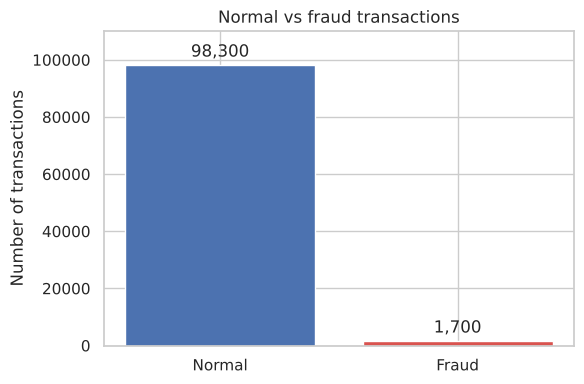

In [5]:
counts = df[TARGET].value_counts().rename({0: "Normal", 1: "Fraud"})
print(counts.to_string())
print(f"\nFraud rate: {df[TARGET].mean():.2%}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=[NORMAL_COLOR, FRAUD_COLOR])
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3)
ax.set_title("Normal vs fraud transactions")
ax.set_ylabel("Number of transactions")
ax.set_ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.savefig(IMG + "class_balance.png", dpi=120)
plt.show()

The data is **very imbalanced**: for every fraud there are about 58 normal transactions.
We will keep this in mind when we train and measure the models.

### 2.2 Are fraud amounts different?

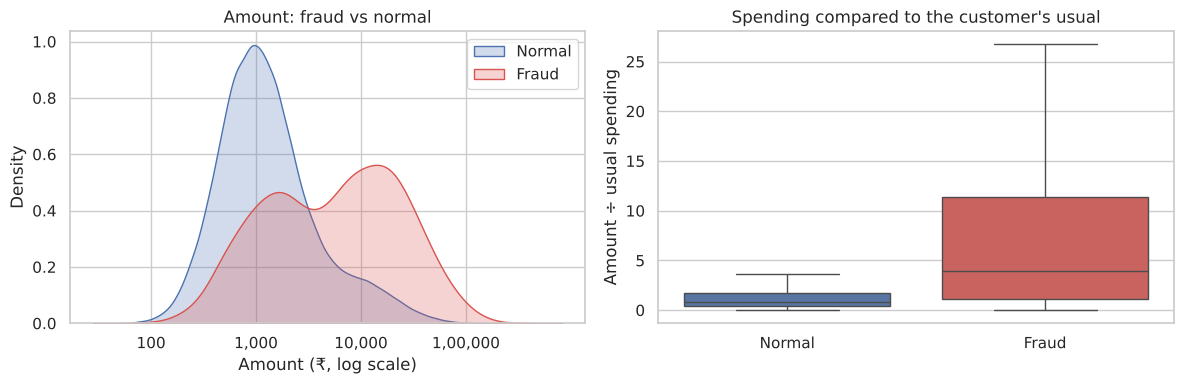

,amount,amount_to_avg_ratio
is_fraud,,
Normal,"1,123.485",0.770
Fraud,"6,169.030",3.940


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color, name in [(0, NORMAL_COLOR, "Normal"), (1, FRAUD_COLOR, "Fraud")]:
    sns.kdeplot(np.log10(df.loc[df[TARGET] == label, "amount"]), ax=axes[0],
                fill=True, color=color, label=name, common_norm=False)
axes[0].set_xlabel("Amount (₹, log scale)")
axes[0].set_xticks([2, 3, 4, 5])
axes[0].set_xticklabels(["100", "1,000", "10,000", "1,00,000"])
axes[0].set_title("Amount: fraud vs normal")
axes[0].legend()

sns.boxplot(data=df, x=TARGET, y="amount_to_avg_ratio", ax=axes[1],
            palette=[NORMAL_COLOR, FRAUD_COLOR], showfliers=False)
axes[1].set_xticklabels(["Normal", "Fraud"])
axes[1].set_xlabel("")
axes[1].set_ylabel("Amount ÷ usual spending")
axes[1].set_title("Spending compared to the customer's usual")
plt.tight_layout()
plt.show()

df.groupby(TARGET)[["amount", "amount_to_avg_ratio"]].median().rename(index={0: "Normal", 1: "Fraud"})

Fraud transactions are usually **bigger**, and much bigger than what the customer normally spends.
But there is a lot of overlap, so amount alone is not enough.

### 2.3 Which shops and channels have the most fraud?

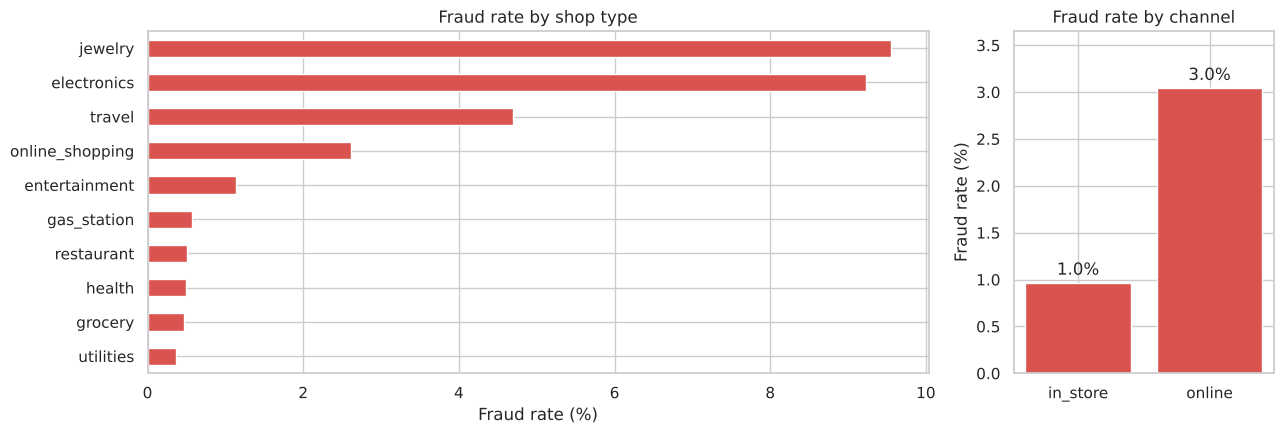

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 1]})

by_cat = df.groupby("merchant_category")[TARGET].mean().sort_values() * 100
by_cat.plot.barh(ax=axes[0], color=FRAUD_COLOR)
axes[0].set_xlabel("Fraud rate (%)")
axes[0].set_ylabel("")
axes[0].set_title("Fraud rate by shop type")

by_channel = df.groupby("channel")[TARGET].mean() * 100
bars = axes[1].bar(by_channel.index, by_channel.values, color=FRAUD_COLOR)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3)
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_ylim(0, by_channel.max() * 1.2)
axes[1].set_title("Fraud rate by channel")
plt.tight_layout()
plt.savefig(IMG + "fraud_by_category.png", dpi=120)
plt.show()

**Jewelry and electronics** have the highest fraud rates. These items are expensive and easy to resell.
**Online** transactions are riskier than in-store ones, because the card is not physically present.

### 2.4 What time of day does fraud happen?

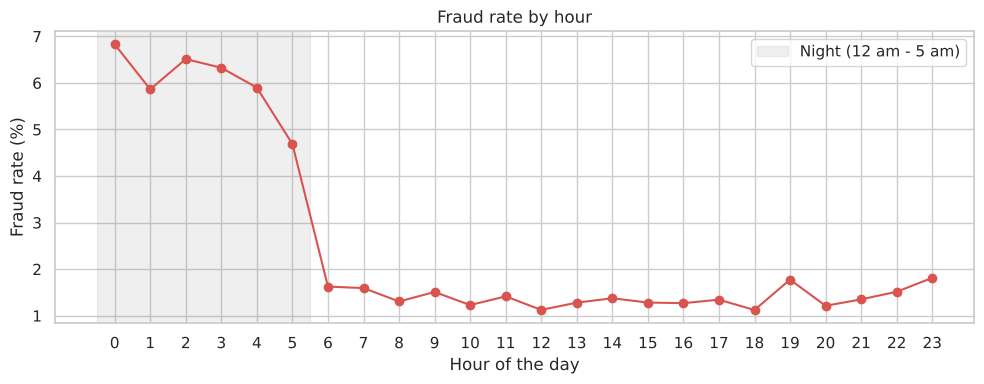

In [8]:
hours = df["transaction_time"].dt.hour
rate_by_hour = df.groupby(hours)[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(rate_by_hour.index, rate_by_hour.values, marker="o", color=FRAUD_COLOR)
ax.axvspan(-0.5, 5.5, color="grey", alpha=0.12, label="Night (12 am - 5 am)")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of the day")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by hour")
ax.legend()
plt.tight_layout()
plt.savefig(IMG + "fraud_by_hour.png", dpi=120)
plt.show()

The fraud rate is much higher **late at night** (12 am to 5 am), when most real customers are asleep.

### 2.5 Yes/No signals

In [9]:
flags = ["is_new_device", "is_new_merchant", "is_international", "used_chip", "used_pin"]
rows = []
for flag in flags:
    rate = df.groupby(flag)[TARGET].mean() * 100
    rows.append({"signal": flag, "fraud rate when 0 (%)": rate[0], "fraud rate when 1 (%)": rate[1]})
pd.DataFrame(rows).set_index("signal")

,fraud rate when 0 (%),fraud rate when 1 (%)
signal,,
is_new_device,1.087,27.691
is_new_merchant,0.666,5.230
is_international,1.351,10.664
used_chip,3.326,0.422
used_pin,2.528,0.343


- A **new device** or an **international** transaction raises the fraud rate a lot.
- Using the **chip** or **PIN** lowers it, because these are hard to copy.

**Summary of what we found:** fraud tends to be large, online or far from home, late at night,
from new devices, at expensive shops, and without chip or PIN. No single signal is enough,
so a model that combines them should do well.

## 3. Create new features

The function `add_features()` in `src/features.py` adds four columns:

| New feature | How it is made | Why it helps |
|---|---|---|
| `hour` | Hour from `transaction_time` | Fraud is more common at night |
| `day_of_week` | Day from `transaction_time` (0 = Monday) | Spending habits change by day |
| `is_night` | 1 if the hour is between 12 am and 5 am | A simple, strong night signal |
| `log_amount` | log(1 + amount) | Stops a few very large amounts from dominating |

The text columns (`channel`, `merchant_category`) are turned into numbers with one-hot encoding
inside each model pipeline.

In [10]:
data = add_features(df)
print("Features used by the model:", len(FEATURES))
data[FEATURES].head()

Features used by the model: 17


,channel,merchant_category,log_amount,amount_to_avg_ratio,distance_from_home_km,distance_from_last_txn_km,txns_last_24h,is_new_device,is_new_merchant,used_chip,used_pin,is_international,card_age_months,customer_age,hour,day_of_week,is_night
0,online,online_shopping,6.140,0.200,4.200,0.700,4,0,0,0,0,0,87,41,0,2,1
1,in_store,gas_station,7.870,3.616,9.300,0.300,3,0,0,1,1,0,31,47,0,2,1
2,online,utilities,8.178,2.133,11.400,33.200,2,0,1,0,0,1,17,31,0,2,1
3,online,online_shopping,8.038,2.455,61.700,50.000,4,0,1,0,0,0,24,51,0,2,1
4,online,jewelry,9.438,5.398,"2,017.600",48.000,5,1,1,0,0,0,21,41,0,2,1


## 4. Split the data

We split the data into three parts:

- **Train (60%)** - the model learns from this
- **Validation (20%)** - used to compare models and choose settings
- **Test (20%)** - kept aside until the very end, to get an honest final score

`stratify` keeps the same fraud rate (1.7%) in every part.

In [11]:
train, temp = train_test_split(data, test_size=0.4, stratify=data[TARGET], random_state=SEED)
valid, test = train_test_split(temp, test_size=0.5, stratify=temp[TARGET], random_state=SEED)

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

for name, part in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:<11} {len(part):>6,} rows   fraud cases: {part[TARGET].sum():>4}   fraud rate: {part[TARGET].mean():.2%}")

Train       60,000 rows   fraud cases: 1020   fraud rate: 1.70%
Validation  20,000 rows   fraud cases:  340   fraud rate: 1.70%
Test        20,000 rows   fraud cases:  340   fraud rate: 1.70%


## 5. Why accuracy is misleading

Let's try a "model" that always says **not fraud**.

In [12]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_valid)
print(f"Accuracy: {accuracy_score(y_valid, dummy_pred):.1%}")
print(f"Fraud caught (recall): {recall_score(y_valid, dummy_pred):.0%}")

Accuracy: 98.3%
Fraud caught (recall): 0%


It is **98.3% accurate** but catches **0% of fraud**, so it is useless.
Instead of accuracy we use these measures:

- **Precision** - of the transactions we flag as fraud, how many really are fraud? (Low precision = many false alarms.)
- **Recall** - of all the real fraud, how much did we catch? (Low recall = fraud gets through.)
- **F1 score** - one number that balances precision and recall.
- **PR-AUC** (average precision) - how well the model ranks fraud above normal transactions, across all thresholds.
  This is the **main measure** for rare events like fraud. A random guess scores about 0.017 here.
- **ROC-AUC** - another ranking measure. It is common, but it can look too good when the data is imbalanced.

## 6. Train and compare three models

| Model | Simple idea | How it handles the imbalance |
|---|---|---|
| Logistic Regression | Adds up weighted signals and turns the total into a probability | `class_weight="balanced"` makes each fraud count more |
| Random Forest | Many decision trees vote together | `class_weight="balanced_subsample"` |
| Gradient Boosting | Builds trees one by one; each new tree fixes the mistakes of the earlier ones | We choose a lower decision threshold later (step 7) |

In [13]:
models = {
    "Logistic Regression": Pipeline([
        ("prep", build_preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Random Forest": Pipeline([
        ("prep", build_preprocessor(scale_numeric=False)),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                         class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=SEED)),
    ]),
    # Same settings as src/train.py
    "Gradient Boosting": Pipeline([
        ("prep", build_preprocessor(scale_numeric=False)),
        ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                 max_leaf_nodes=31, l2_regularization=1.0,
                                                 random_state=SEED)),
    ]),
}

results, valid_probs = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_valid)[:, 1]
    pred = (prob >= 0.5).astype(int)
    valid_probs[name] = prob
    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_valid, prob),
        "ROC-AUC": roc_auc_score(y_valid, prob),
        "Precision @0.5": precision_score(y_valid, pred),
        "Recall @0.5": recall_score(y_valid, pred),
        "F1 @0.5": f1_score(y_valid, pred),
    })

results = pd.DataFrame(results).set_index("Model").sort_values("PR-AUC", ascending=False)
results

,PR-AUC,ROC-AUC,Precision @0.5,Recall @0.5,F1 @0.5
Model,,,,,
Gradient Boosting,0.749,0.942,0.838,0.591,0.693
Random Forest,0.722,0.942,0.653,0.753,0.699
Logistic Regression,0.572,0.934,0.232,0.871,0.367


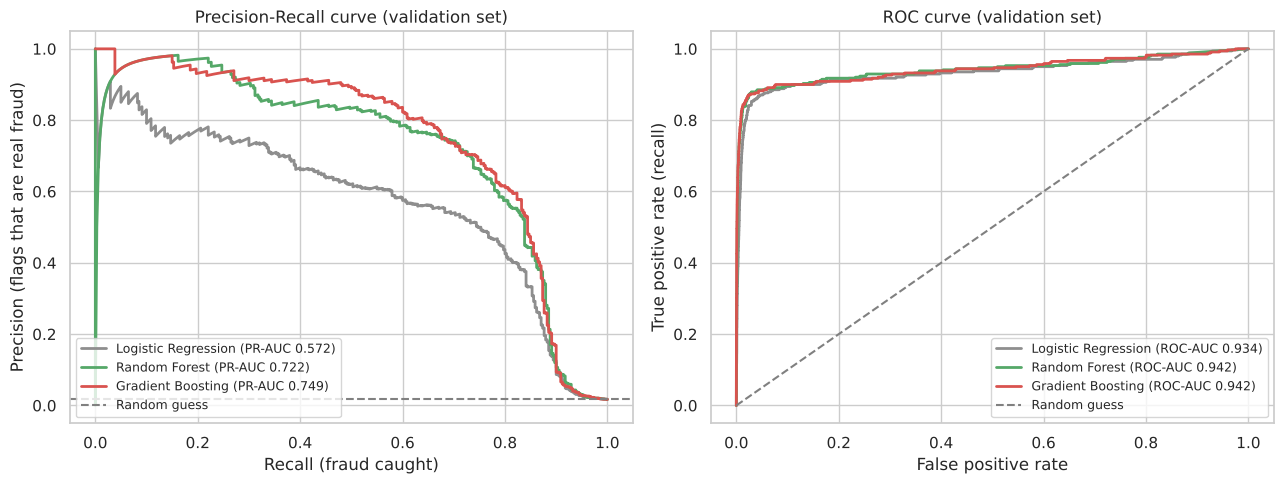

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"Logistic Regression": "#8E8E8E", "Random Forest": "#55A868", "Gradient Boosting": FRAUD_COLOR}

for name, prob in valid_probs.items():
    p, r, _ = precision_recall_curve(y_valid, prob)
    axes[0].plot(r, p, color=colors[name], lw=2,
                 label=f"{name} (PR-AUC {average_precision_score(y_valid, prob):.3f})")
    fpr, tpr, _ = roc_curve(y_valid, prob)
    axes[1].plot(fpr, tpr, color=colors[name], lw=2,
                 label=f"{name} (ROC-AUC {roc_auc_score(y_valid, prob):.3f})")

axes[0].axhline(y_valid.mean(), ls="--", color="grey", label="Random guess")
axes[0].set(xlabel="Recall (fraud caught)", ylabel="Precision (flags that are real fraud)",
            title="Precision-Recall curve (validation set)")
axes[1].plot([0, 1], [0, 1], ls="--", color="grey", label="Random guess")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate (recall)",
            title="ROC curve (validation set)")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[0] else "lower right", fontsize=9)
plt.tight_layout()
plt.savefig(IMG + "model_comparison.png", dpi=120)
plt.show()

**Gradient Boosting** has the best PR-AUC, so it ranks fraud above normal transactions better than
the other two models. Its recall at the default 0.5 threshold looks low, but that only means 0.5 is
the wrong cut-off for rare fraud. We fix that in the next step.

We pick **Gradient Boosting** as our final model.

## 7. Choose the decision threshold

The model gives each transaction a **fraud probability** between 0 and 1.
The **threshold** is the cut-off: above it, we flag the transaction as fraud.

- A **lower** threshold catches more fraud (higher recall) but gives more false alarms (lower precision).
- A **higher** threshold gives fewer false alarms but misses more fraud.

We choose the threshold with the best F1 score on the **validation** set (never on the test set).

Best threshold: 0.24  ->  precision 70.4%, recall 74.1%, F1 0.722


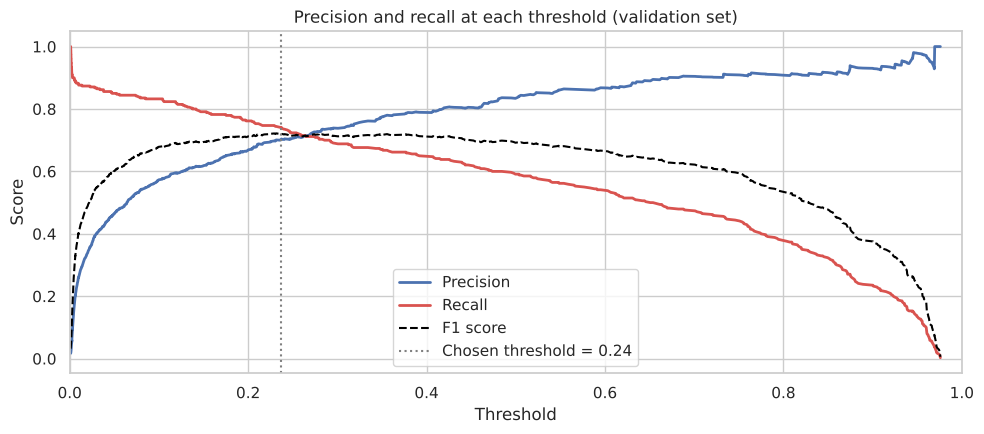

In [15]:
best_model = models["Gradient Boosting"]
prob_valid = valid_probs["Gradient Boosting"]

precision, recall, thresholds = precision_recall_curve(y_valid, prob_valid)
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-9, None)
best_idx = np.argmax(f1[:-1])
THRESHOLD = thresholds[best_idx]
print(f"Best threshold: {THRESHOLD:.2f}  ->  precision {precision[best_idx]:.1%}, "
      f"recall {recall[best_idx]:.1%}, F1 {f1[best_idx]:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thresholds, precision[:-1], label="Precision", color=NORMAL_COLOR, lw=2)
ax.plot(thresholds, recall[:-1], label="Recall", color=FRAUD_COLOR, lw=2)
ax.plot(thresholds, f1[:-1], label="F1 score", color="black", lw=1.5, ls="--")
ax.axvline(THRESHOLD, color="grey", ls=":", label=f"Chosen threshold = {THRESHOLD:.2f}")
ax.set(xlabel="Threshold", ylabel="Score", title="Precision and recall at each threshold (validation set)", xlim=(0, 1))
ax.legend()
plt.tight_layout()
plt.savefig(IMG + "threshold.png", dpi=120)
plt.show()

In [16]:
# The trade-off at a few thresholds
rows = []
for t in [0.1, 0.2, round(THRESHOLD, 2), 0.3, 0.5, 0.7]:
    pred = (prob_valid >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_valid, pred),
                 "recall": recall_score(y_valid, pred),
                 "transactions flagged": int(pred.sum())})
pd.DataFrame(rows).drop_duplicates("threshold").set_index("threshold")

,precision,recall,transactions flagged
threshold,,,
0.100,0.574,0.832,493
0.200,0.669,0.762,387
0.240,0.702,0.735,356
0.300,0.738,0.688,317
0.500,0.838,0.591,240
0.700,0.904,0.474,178


A bank can move the threshold based on its needs. If missing fraud is very costly, it can lower
the threshold and accept more false alarms that staff will review.

## 8. Final results on the test set

Now we check the final model, with the chosen threshold, on the **test set**: 20,000 transactions
the model has never seen.

In [17]:
prob_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()

final = pd.Series({
    "Precision": precision_score(y_test, pred_test),
    "Recall": recall_score(y_test, pred_test),
    "F1 score": f1_score(y_test, pred_test),
    "ROC-AUC": roc_auc_score(y_test, prob_test),
    "PR-AUC": average_precision_score(y_test, prob_test),
}, name="Test set")
print(final.to_string(float_format="{:.3f}".format))
print(f"\nFraud caught: {tp} of {tp + fn}   |   False alarms: {fp} of {tn + fp:,} normal transactions")

Precision   0.692
Recall      0.732
F1 score    0.711
ROC-AUC     0.942
PR-AUC      0.767

Fraud caught: 249 of 340   |   False alarms: 111 of 19,660 normal transactions


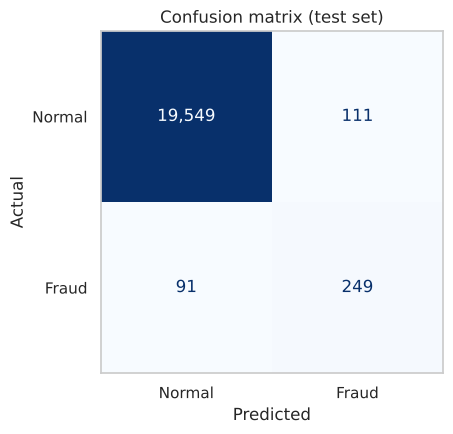

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["Normal", "Fraud"]).plot(ax=ax, cmap="Blues", values_format=",", colorbar=False)
ax.set(title="Confusion matrix (test set)", xlabel="Predicted", ylabel="Actual")
ax.grid(False)
plt.tight_layout()
plt.savefig(IMG + "confusion_matrix.png", dpi=120)
plt.show()

**In plain words:** out of every 4 fraud transactions, the model catches about 3. Only about
**0.6%** of normal transactions are wrongly flagged, so customers are rarely bothered.

The fraud it misses is mostly the "looks normal" kind. These transactions have no warning signs
in the data, so no model could catch them without more information (for example, the customer's
full purchase history).

## 9. Which features matter most?

We use **permutation importance**: shuffle one column at a time and see how much the model's
PR-AUC drops. A big drop means the model depends on that column a lot.

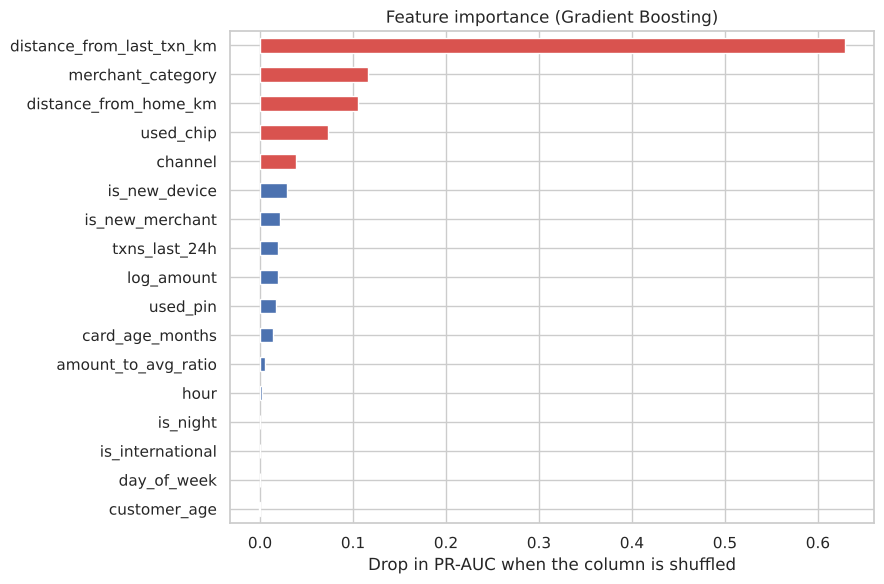

,importance
distance_from_last_txn_km,0.629
merchant_category,0.116
distance_from_home_km,0.105
used_chip,0.073
channel,0.039


In [19]:
imp = permutation_importance(best_model, X_valid, y_valid, scoring="average_precision",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
importance.plot.barh(ax=ax, color=[FRAUD_COLOR if v >= importance.nlargest(5).min() else NORMAL_COLOR
                                   for v in importance])
ax.set(xlabel="Drop in PR-AUC when the column is shuffled", ylabel="",
       title="Feature importance (Gradient Boosting)")
plt.tight_layout()
plt.savefig(IMG + "feature_importance.png", dpi=120)
plt.show()

importance.sort_values(ascending=False).head(5).to_frame("importance")

The model depends most on **distance from the last transaction**. If a card is used in one place
and then soon after somewhere far away, it is a classic sign that the card was copied or stolen.
Next come the **shop type**, **distance from home**, whether the **chip** was used, and the
**channel** (online or in-store).

Amount and time of day score low here, even though they looked different for fraud in section 2.
This is because their information overlaps with other columns (for example, jewelry and electronics
are already expensive), so shuffling just one of them does not hurt the model much.
Low permutation importance does not always mean a feature is useless.

## 10. Conclusion

- Fraud is only 1.7% of transactions, so **accuracy is misleading**. We used precision, recall, F1 and PR-AUC instead.
- **Gradient Boosting** was the best of three models.
- With a tuned threshold, it catches about **3 out of 4** fraud transactions while flagging less than **1%** of normal ones.
- The strongest warning signs are a big jump in distance from the last transaction, risky shop types (jewelry, electronics), distance from home, and not using the card chip.

**Next steps to improve the model**
- Add customer history features (for example, spending in the last 7 days).
- Tune the model settings with cross-validation.
- Set the threshold using real costs (the cost of missed fraud vs the cost of reviewing a false alarm).
- Test the same steps on a real public dataset, such as the
  [Kaggle credit card fraud dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).

**Use the model:** run `python src/train.py` to train and save it, then `python src/predict.py`
to check new transactions.